# **Exercise 3 – Regularization and Generalization**
*Group 74 : AI-ML Assessment 1*

**Intruduction**

In this problem, we study how different types of regularization affect the generization performance of a CNN trained on the CIFAR-10 dataset.

The experiment focuses on two methods: dropout and data augmentation. The two methods will be analyzed separately in order to measure the effect of each on overfitting.

The base CNN from Exercise 2 will serve as the benchmark network. Much of the CNN architecture and configuration  will be kept intact for a fair comparison.



**Exprimental Design**

The CNN model developed in Exercise 2 serves as the starting point for comparison. It is made up of two convolutional layers having 32 and 64 channels respectively, along with an output fully connected layer of 10 neurons.



*   Baseline: The original CNN without dropout or data augmentation.
*   Dropout: The baseline CNN modified by introducing a dropout layer with a probability of 0.3.
*   Data augmentation: The baseline CNN trained using augmented training images, while retaining the original model architecture.


The model that performs the best on validation will be chosen for testing. The test dataset is not used for hyperparameter selection.







---

# Reusing the baseline preperation


# 1.Imports

In [1]:
import sys, time, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import copy


import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# group settings
SEED        = 42
BATCH_SIZE  = 128
EPOCHS      = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.0
VAL_SIZE    = 5000            # from train set only
NUM_WORKERS = 0
DATA_DIR    = "./data"

# normalisation values
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

CLASS_NAMES = ["aeroplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {device}")

Python 3.13.16 | PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
Device: cuda


In [2]:
import platform

def cpu_name():
    try:
        with open("/proc/cpuinfo") as f:
            for line in f:
                if "model name" in line:
                    return line.split(":")[1].strip()
    except OSError:
        pass
    return platform.processor() or platform.machine()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)
print("CPU:", cpu_name())
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Device: cuda
CPU: Intel(R) Xeon(R) CPU @ 2.00GHz
GPU: Tesla T4


# 2.Random seed setup

In [3]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


# 3.CIFAR-10 Dataset Preparation and Train/Validation Split

In [4]:
# No augmentation here
base_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

train_transform = base_transform
eval_transform = base_transform

# Load data
full_train_for_train = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

full_train_for_val = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    DATA_DIR,
    train=False,
    download=True,
    transform=eval_transform
)

# 45k train / 5k validation split
split_generator = torch.Generator().manual_seed(SEED)

perm = torch.randperm(
    len(full_train_for_train),
    generator=split_generator
).numpy()

val_indices = np.sort(perm[:VAL_SIZE])
train_indices = np.sort(perm[VAL_SIZE:])

train_dataset = Subset(
    full_train_for_train,
    train_indices.tolist()
)

validation_dataset = Subset(
    full_train_for_val,
    val_indices.tolist()
)

# Same value everywhere = same split
split_hash = hashlib.md5(val_indices.tobytes()).hexdigest()

print(
    f"Split seed: {SEED} | "
    f"validation-index fingerprint (md5): {split_hash}"
)

100%|██████████| 170M/170M [13:06<00:00, 217kB/s]


Split seed: 42 | validation-index fingerprint (md5): d45cf7fe22a123b42b27274bddc38a8e


# 4.DataLoaders

In [5]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                          generator=loader_generator, pin_memory=(device.type == "cuda"))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

# 5.Dataset Sanity Checks

Train / Val / Test sizes: 45000 / 5000 / 10000
Batch shape: (128, 3, 32, 32) | label dtype: torch.int64
Per-channel batch mean (should be near 0): [-0.039 -0.037 -0.034]
Per-channel batch std  (should be near 1): [1.016 1.017 1.003]
All sanity checks passed.


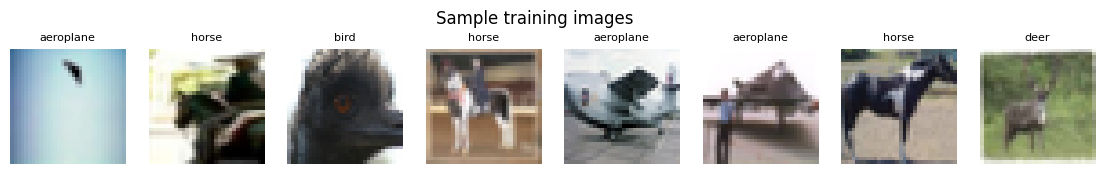

In [6]:
assert len(train_dataset) == 45000,      f"Train size is {len(train_dataset)}"
assert len(validation_dataset) == 5000,  f"Validation size is {len(validation_dataset)}"
assert len(test_dataset) == 10000,       f"Test size is {len(test_dataset)}"
assert len(set(train_indices) & set(val_indices)) == 0, "Train/validation overlap!"
assert len(train_indices) + len(val_indices) == 50000

images, labels = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {images.shape}"
assert labels.min() >= 0 and labels.max() <= 9, "Labels outside 0-9"
assert torch.isfinite(images).all(), "Non-finite pixel values"

print(f"Train / Val / Test sizes: {len(train_dataset)} / {len(validation_dataset)} / {len(test_dataset)}")
print(f"Batch shape: {tuple(images.shape)} | label dtype: {labels.dtype}")
print("Per-channel batch mean (should be near 0):", images.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel batch std  (should be near 1):", images.std(dim=(0, 2, 3)).numpy().round(3))
print("All sanity checks passed.")

# look at a few images
mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, images[:8], labels[:8]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

# 6.Baseline CNN Architecture

In [7]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Trainable Layer 1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Trainable Layer 2
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # Non-trainable operations
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        # Trainable Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Flatten feature maps
        x = self.flatten(x)

        # Classification layer
        x = self.fc(x)

        return x

# Experimental Design

The baseline CNN, as defined in Exercise 2, is taken as the reference CNN. The following two experiments are done separately:
1. Dropout: A dropout layer is added to the baseline CNN for reducing overfitting by turning off some of the neurons randomly.
2. Data Augmentation: Transformations are done to training images for increasing the variability of training data.

The experiments use the same CIFAR-10 dataset, training and validation split, batch size, optimiser, learning rate, weight decay, and number of epochs as the baseline experiment.

# Baseline CNN Reference Results



In [8]:
# Baseline CNN results from Exercise 2

baseline_results = {
    "Experiment": "Baseline CNN",
    "Best Epoch": 14,
    "Train Accuracy (%)": 84.75,
    "Validation Accuracy (%)": 71.82,
    "Test Accuracy (%)": 70.72,
    "Train Loss": 0.4410,
    "Validation Loss": 0.9175,
    "Test Loss": 0.9504,
    "Parameters": 60362,
    "Training Time (seconds)": 489.4
}

baseline_df = pd.DataFrame([baseline_results])

display(baseline_df)

,Experiment,Best Epoch,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train Loss,Validation Loss,Test Loss,Parameters,Training Time (seconds)
0,Baseline CNN,14,84.75,71.82,70.72,0.441,0.9175,0.9504,60362,489.4




---

# Dropout Experiment


In this experiment, the addition of dropout with probability 0.3 is done after the flattening layer and before the fully connected classification layer.

This means random deactivation of about 30% of the flattened features at each training iteration. Dropout is automatically disabled at the time of evaluation.

Other architectural and training parameters have been kept the same as the base model in order to study the impact of dropout independently.

**Dropout CNN Architecture**

The dropout model follows the same architecture as the baseline CNN, with one additional dropout layer.



*   Two convolutional layers.
*   ReLU activation functions.
*   Two max-pooling operations.
*   A flattening operation.
*   A dropout layer with a probability of 0.3.
*   A fully connected output layer with 10 neurons.

The dropout layer does not introduce additional trainable parameters. Therefore, the total number of trainable parameters remains the same as the baseline CNN.

# 1.Creating the dropout model

In [9]:
class DropoutCNN(nn.Module):
    def __init__(self, dropout_probability=0.3):
        super().__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Second convolutional layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # Non-trainable operations
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        # Dropout layer
        self.dropout = nn.Dropout(p=dropout_probability)

        # Fully connected classification layer
        self.fc = nn.Linear(64 * 8 * 8, 10)

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Flatten feature maps
        x = self.flatten(x)

        # Apply dropout
        x = self.dropout(x)

        # Classification layer
        x = self.fc(x)

        return x

# 2.Checking the architecture and parameter count

In [10]:
set_seed(SEED)

dropout_model = DropoutCNN(dropout_probability=0.3).to(device)

print(dropout_model)

dropout_parameters = sum(
    p.numel()
    for p in dropout_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", dropout_parameters)

assert dropout_parameters == 60362, \
    "Unexpected number of trainable parameters!"

print("Dropout CNN architecture checks passed!")

DropoutCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable parameters: 60362
Dropout CNN architecture checks passed!


# 3.Evaluation Function

In [11]:
def evaluate_model(model, data_loader, criterion):

    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples

    accuracy = (
        correct_predictions / total_samples
    ) * 100

    return average_loss, accuracy

# 4.Creating the Training Evaluation DataLoader

In [12]:
dropout_train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

print("Dropout training evaluation DataLoader created.")

Dropout training evaluation DataLoader created.


# 5.Dropout Model Training Function

The dropout CNN is trained from scratch using the same training configuration as the baseline model.


*   Optimizer: Adam
*   Learning rate: 0.001
*   Weight decay: 0.0
*   Batch size: 128
*   Number of epochs: 20
*   Loss function: Cross-Entropy Loss

After every epoch of training, the model is evaluated using the training and validation datasets. Only the checkpoint that achieves the highest validation accuracy is saved.

After training, the best checkpoint is restored and evaluated using the official test dataset.







In [13]:
def train_model(
    model,
    train_loader,
    train_eval_loader,
    validation_loader,
    epochs=EPOCHS
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": []
    }

    best_validation_accuracy = -1.0
    best_epoch = 0
    best_model_state = None

    start_time = time.perf_counter()

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_samples += batch_size

        epoch_train_loss = running_loss / total_samples

        epoch_train_accuracy = (
            correct_predictions / total_samples
        ) * 100

        # evaluate training and validation performance
        train_eval_loss, train_eval_accuracy = evaluate_model(
            model,
            train_eval_loader,
            criterion
        )

        validation_loss, validation_accuracy = evaluate_model(
            model,
            validation_loader,
            criterion
        )

        history["train_loss"].append(train_eval_loss)
        history["train_accuracy"].append(train_eval_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)

        # select the best checkpoint using validation accuracy
        if validation_accuracy > best_validation_accuracy:

            best_validation_accuracy = validation_accuracy
            best_epoch = epoch + 1

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"| Train Loss: {train_eval_loss:.4f} "
            f"| Train Acc: {train_eval_accuracy:.2f}% "
            f"| Val Loss: {validation_loss:.4f} "
            f"| Val Acc: {validation_accuracy:.2f}%"
        )

    training_time = time.perf_counter() - start_time

    # restore the best validation checkpoint
    model.load_state_dict(best_model_state)

    print("\nTraining completed.")
    print("Best epoch:", best_epoch)
    print(
        f"Best validation accuracy: "
        f"{best_validation_accuracy:.2f}%"
    )
    print(f"Training time: {training_time:.2f} seconds")

    return model, history, best_epoch, training_time

# 6.Training the Dropout Model

In [ ]:
set_seed(SEED)

# dedicated training DataLoader
dropout_generator = torch.Generator().manual_seed(SEED)

dropout_train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=dropout_generator,
    pin_memory=(device.type == "cuda")
)

# fresh dropout model
dropout_model = DropoutCNN(
    dropout_probability=0.3
).to(device)

# train the model
dropout_model, dropout_history, dropout_best_epoch, dropout_training_time = train_model(
    model=dropout_model,
    train_loader=dropout_train_loader,
    train_eval_loader=dropout_train_eval_loader,
    validation_loader=validation_loader,
    epochs=EPOCHS
)

Epoch [1/20] | Train Loss: 1.1264 | Train Acc: 60.95% | Val Loss: 1.1564 | Val Acc: 58.64%
Epoch [2/20] | Train Loss: 0.9859 | Train Acc: 66.38% | Val Loss: 1.0457 | Val Acc: 64.24%
Epoch [3/20] | Train Loss: 0.8777 | Train Acc: 69.65% | Val Loss: 0.9609 | Val Acc: 67.34%
Epoch [4/20] | Train Loss: 0.7929 | Train Acc: 73.20% | Val Loss: 0.8992 | Val Acc: 69.32%
Epoch [5/20] | Train Loss: 0.7359 | Train Acc: 74.94% | Val Loss: 0.8549 | Val Acc: 70.24%
Epoch [6/20] | Train Loss: 0.6992 | Train Acc: 76.18% | Val Loss: 0.8438 | Val Acc: 71.40%
Epoch [7/20] | Train Loss: 0.6683 | Train Acc: 77.54% | Val Loss: 0.8319 | Val Acc: 72.02%
Epoch [8/20] | Train Loss: 0.6312 | Train Acc: 78.59% | Val Loss: 0.8146 | Val Acc: 72.42%
Epoch [9/20] | Train Loss: 0.6074 | Train Acc: 79.98% | Val Loss: 0.8011 | Val Acc: 73.14%
Epoch [10/20] | Train Loss: 0.5981 | Train Acc: 79.39% | Val Loss: 0.8188 | Val Acc: 71.72%
Epoch [11/20] | Train Loss: 0.5403 | Train Acc: 81.88% | Val Loss: 0.7716 | Val Acc: 73.8

# 7.Evaluating the Best Dropout Model

In [ ]:
criterion = nn.CrossEntropyLoss()

# evaluate the restored best checkpoint
dropout_train_loss, dropout_train_accuracy = evaluate_model(
    dropout_model,
    dropout_train_eval_loader,
    criterion
)

dropout_val_loss, dropout_val_accuracy = evaluate_model(
    dropout_model,
    validation_loader,
    criterion
)

# evaluate the test set
dropout_test_loss, dropout_test_accuracy = evaluate_model(
    dropout_model,
    test_loader,
    criterion
)

dropout_accuracy_gap = (
    dropout_train_accuracy - dropout_val_accuracy
)

dropout_parameters = sum(
    p.numel()
    for p in dropout_model.parameters()
    if p.requires_grad
)

# Store the results
dropout_results = {
    "Experiment": "Dropout (p=0.3)",
    "Best Epoch": dropout_best_epoch,
    "Train Accuracy (%)": dropout_train_accuracy,
    "Validation Accuracy (%)": dropout_val_accuracy,
    "Test Accuracy (%)": dropout_test_accuracy,
    "Train Loss": dropout_train_loss,
    "Validation Loss": dropout_val_loss,
    "Test Loss": dropout_test_loss,
    "Accuracy Gap (%)": dropout_accuracy_gap,
    "Parameters": dropout_parameters,
    "Training Time (seconds)": dropout_training_time
}

dropout_df = pd.DataFrame([dropout_results])

display(dropout_df)

print("\nDropout experiment completed successfully.")

,Experiment,Best Epoch,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train Loss,Validation Loss,Test Loss,Accuracy Gap (%),Parameters,Training Time (seconds)
0,Dropout (p=0.3),19,85.58,75.08,74.68,0.434273,0.760243,0.766265,10.5,60362,2477.245686



Dropout experiment completed successfully.


**Save the best checkpoint**

In [ ]:
torch.save(
    dropout_model.state_dict(),
    "cnn_dropout_best_validation.pth"
)

print("Best dropout checkpoint saved.")

Best dropout checkpoint saved.


# 8.Visualizing Dropout Training Performance

**Loss plot**

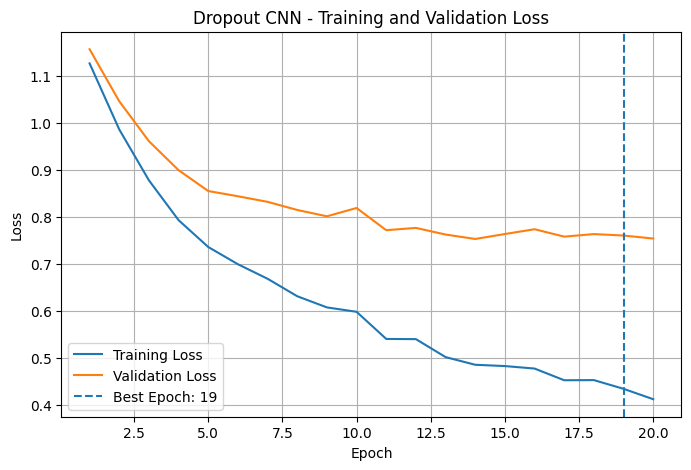

In [ ]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    dropout_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    dropout_history["validation_loss"],
    label="Validation Loss"
)

plt.axvline(
    dropout_best_epoch,
    linestyle="--",
    label=f"Best Epoch: {dropout_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dropout CNN - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    "dropout_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Accuracy plot**

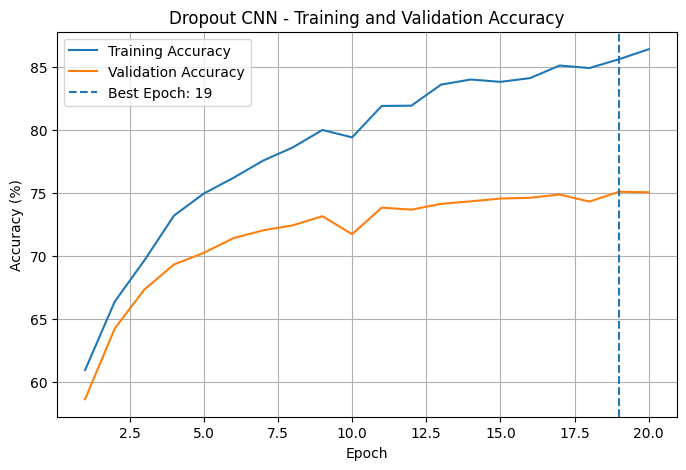

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    dropout_history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    dropout_history["validation_accuracy"],
    label="Validation Accuracy"
)

plt.axvline(
    dropout_best_epoch,
    linestyle="--",
    label=f"Best Epoch: {dropout_best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Dropout CNN - Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    "dropout_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Dropout Experiment Results

The dropout experiment was conducted using a dropout probability of 0.3.

The model was trained for 20 epochs, and the checkpoint with the highest validation accuracy was selected.

The final training, validation, and test metrics are presented below. These results will be compared with the baseline CNN to evaluate whether dropout improved generalization performance.

In [ ]:
print("DROPOUT EXPERIMENT SUMMARY")
print("-" * 40)

print(f"Best epoch: {dropout_best_epoch}")
print(f"Training accuracy: {dropout_train_accuracy:.2f}%")
print(f"Validation accuracy: {dropout_val_accuracy:.2f}%")
print(f"Test accuracy: {dropout_test_accuracy:.2f}%")

print(f"Training loss: {dropout_train_loss:.4f}")
print(f"Validation loss: {dropout_val_loss:.4f}")
print(f"Test loss: {dropout_test_loss:.4f}")

print(f"Accuracy gap: {dropout_accuracy_gap:.2f} percentage points")
print(f"Trainable parameters: {dropout_parameters}")
print(f"Training time: {dropout_training_time:.2f} seconds")

DROPOUT EXPERIMENT SUMMARY
----------------------------------------
Best epoch: 19
Training accuracy: 85.58%
Validation accuracy: 75.08%
Test accuracy: 74.68%
Training loss: 0.4343
Validation loss: 0.7602
Test loss: 0.7663
Accuracy gap: 10.50 percentage points
Trainable parameters: 60362
Training time: 2477.25 seconds


---

# Data Augmentation Experiment

In this experiment, data augmentation is applied to the training images only, while the baseline CNN architecture is kept exactly the same.

Two random transformations are applied to each training image every time it is loaded: a random crop with 4 pixels of padding, which shifts the object slightly, and a random horizontal flip with a probability of 0.5, which mirrors the image left to right. This means the model sees a slightly different version of each image in every epoch.

Validation and test images are not augmented. Other architectural and training parameters have been kept the same as the base model in order to study the impact of data augmentation independently.

**Data Augmentation Setup**

The augmentation model uses the same architecture as the baseline CNN, with no changes to the layers.

*   Two convolutional layers (32 and 64 channels).
*   ReLU activation functions.
*   Two max-pooling operations.
*   A flattening operation.
*   A fully connected output layer with 10 neurons.
*   Training transform: RandomCrop(32, padding=4) and RandomHorizontalFlip(p=0.5), applied before ToTensor() and normalisation.

These transformations keep the CIFAR-10 labels correct, because a shifted or mirrored car is still a car. Vertical flips and large rotations were not used because they create unrealistic images, such as upside-down ships.

Data augmentation does not add any trainable parameters. Therefore, the total number of trainable parameters remains the same as the baseline CNN (60,362). Training accuracy and loss are measured on the non-augmented training images so that they can be compared directly with the baseline and dropout results.

# 1.Creating the augmented training dataset

In [14]:
augment_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

full_train_augmented = datasets.CIFAR10(
    DATA_DIR,
    train=True,
    download=True,
    transform=augment_transform
)

augmented_train_dataset = Subset(
    full_train_augmented,
    train_indices.tolist()
)

# Split checks
assert len(augmented_train_dataset) == 45000, "Augmented training set must contain 45,000 images"
assert augmented_train_dataset.indices == train_dataset.indices, "Training indices differ from the baseline split!"
assert hashlib.md5(val_indices.tobytes()).hexdigest() == split_hash, "Validation split has changed!"
assert len(set(augmented_train_dataset.indices) & set(val_indices.tolist())) == 0, "Train/validation overlap!"

print("Augmented training images:", len(augmented_train_dataset))
print("Validation images (unchanged, no augmentation):", len(validation_dataset))
print("Test images (unchanged, no augmentation):", len(test_dataset))
print(f"Validation-index fingerprint (md5): {split_hash}")
print("Augmented dataset uses the same split as the baseline.")

Augmented training images: 45000
Validation images (unchanged, no augmentation): 5000
Test images (unchanged, no augmentation): 10000
Validation-index fingerprint (md5): d45cf7fe22a123b42b27274bddc38a8e
Augmented dataset uses the same split as the baseline.


# 2.Visualising the augmentation

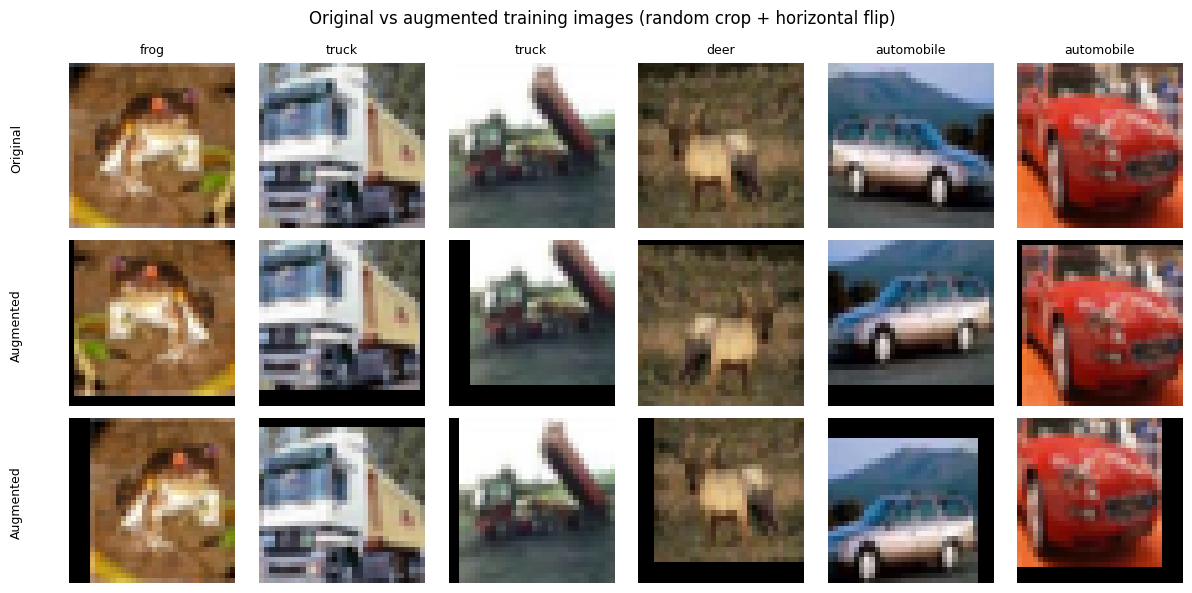

In [15]:
set_seed(SEED)

mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)

def denormalise(img):
    return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0)

sample_positions = range(6)
fig, axes = plt.subplots(3, 6, figsize=(12, 6))

for col, pos in enumerate(sample_positions):
    original_img, label = train_dataset[pos]
    axes[0, col].imshow(denormalise(original_img))
    axes[0, col].set_title(CLASS_NAMES[label], fontsize=9)
    for row in (1, 2):
        aug_img, _ = augmented_train_dataset[pos]
        axes[row, col].imshow(denormalise(aug_img))

for ax in axes.flat:
    ax.axis("off")

axes[0, 0].text(-12, 16, "Original", rotation=90, va="center", fontsize=9)
axes[1, 0].text(-12, 16, "Augmented", rotation=90, va="center", fontsize=9)
axes[2, 0].text(-12, 16, "Augmented", rotation=90, va="center", fontsize=9)

plt.suptitle("Original vs augmented training images (random crop + horizontal flip)")
plt.tight_layout()
plt.savefig("augmentation_examples.png", dpi=300, bbox_inches="tight")
plt.show()

# 3.Augmentation DataLoaders

In [16]:
set_seed(SEED)

augmentation_generator = torch.Generator().manual_seed(SEED)

augmentation_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=augmentation_generator,
    pin_memory=(device.type == "cuda")
)

augmentation_train_eval_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

aug_images, aug_labels = next(iter(augmentation_train_loader))
assert aug_images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {aug_images.shape}"
assert torch.isfinite(aug_images).all(), "Non-finite pixel values"

print("Augmented batch shape:", tuple(aug_images.shape))
print("Augmentation DataLoaders created.")

Augmented batch shape: (128, 3, 32, 32)
Augmentation DataLoaders created.


# 4.Training the baseline CNN with augmented data

A fresh, unchanged `BaselineCNN` is trained from scratch using the same training function and configuration as the dropout experiment (Adam, learning rate 0.001, weight decay 0.0, batch size 128, 20 epochs, cross-entropy loss). The checkpoint with the highest validation accuracy is restored after training.

In [17]:
set_seed(SEED)

augmentation_model = BaselineCNN().to(device)

augmentation_parameters = sum(
    p.numel()
    for p in augmentation_model.parameters()
    if p.requires_grad
)

print(augmentation_model)
print("Trainable parameters:", augmentation_parameters)

assert augmentation_parameters == 60362, "Architecture differs from the baseline CNN!"

augmentation_model, augmentation_history, augmentation_best_epoch, augmentation_training_time = train_model(
    model=augmentation_model,
    train_loader=augmentation_train_loader,
    train_eval_loader=augmentation_train_eval_loader,
    validation_loader=validation_loader,
    epochs=EPOCHS
)

BaselineCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=4096, out_features=10, bias=True)
)
Trainable parameters: 60362
Epoch [1/20] | Train Loss: 1.3150 | Train Acc: 53.42% | Val Loss: 1.3287 | Val Acc: 53.46%
Epoch [2/20] | Train Loss: 1.0750 | Train Acc: 62.55% | Val Loss: 1.0861 | Val Acc: 63.04%
Epoch [3/20] | Train Loss: 0.9720 | Train Acc: 66.48% | Val Loss: 0.9859 | Val Acc: 66.06%
Epoch [4/20] | Train Loss: 0.9426 | Train Acc: 67.21% | Val Loss: 0.9594 | Val Acc: 66.94%
Epoch [5/20] | Train Loss: 0.8858 | Train Acc: 69.07% | Val Loss: 0.9181 | Val Acc: 68.36%
Epoch [6/20] | Train Loss: 0.9044 | Train Acc: 68.69% | Val Loss: 0.9287 | Val Acc: 68.94%
Epoch [7/20] | Train Loss: 0.8188 | Train Acc: 71

# 5.Evaluating the best augmentation model

In [18]:
criterion = nn.CrossEntropyLoss()

aug_train_loss, aug_train_accuracy = evaluate_model(
    augmentation_model,
    augmentation_train_eval_loader,
    criterion
)

aug_val_loss, aug_val_accuracy = evaluate_model(
    augmentation_model,
    validation_loader,
    criterion
)

aug_test_loss, aug_test_accuracy = evaluate_model(
    augmentation_model,
    test_loader,
    criterion
)

aug_accuracy_gap = aug_train_accuracy - aug_val_accuracy

augmentation_results = {
    "Experiment": "Data Augmentation (crop + flip)",
    "Best Epoch": augmentation_best_epoch,
    "Train Accuracy (%)": aug_train_accuracy,
    "Validation Accuracy (%)": aug_val_accuracy,
    "Test Accuracy (%)": aug_test_accuracy,
    "Train Loss": aug_train_loss,
    "Validation Loss": aug_val_loss,
    "Test Loss": aug_test_loss,
    "Accuracy Gap (%)": aug_accuracy_gap,
    "Parameters": augmentation_parameters,
    "Training Time (seconds)": augmentation_training_time
}

augmentation_df = pd.DataFrame([augmentation_results])
display(augmentation_df)

torch.save(
    augmentation_model.state_dict(),
    "cnn_augmentation_best_validation.pth"
)

print("\nBest augmentation checkpoint saved.")

,Experiment,Best Epoch,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train Loss,Validation Loss,Test Loss,Accuracy Gap (%),Parameters,Training Time (seconds)
0,Data Augmentation (crop + flip),20,76.502222,75.6,74.68,0.681756,0.729282,0.741433,0.902222,60362,578.259962



Best augmentation checkpoint saved.


# 6.Visualising augmentation training performance

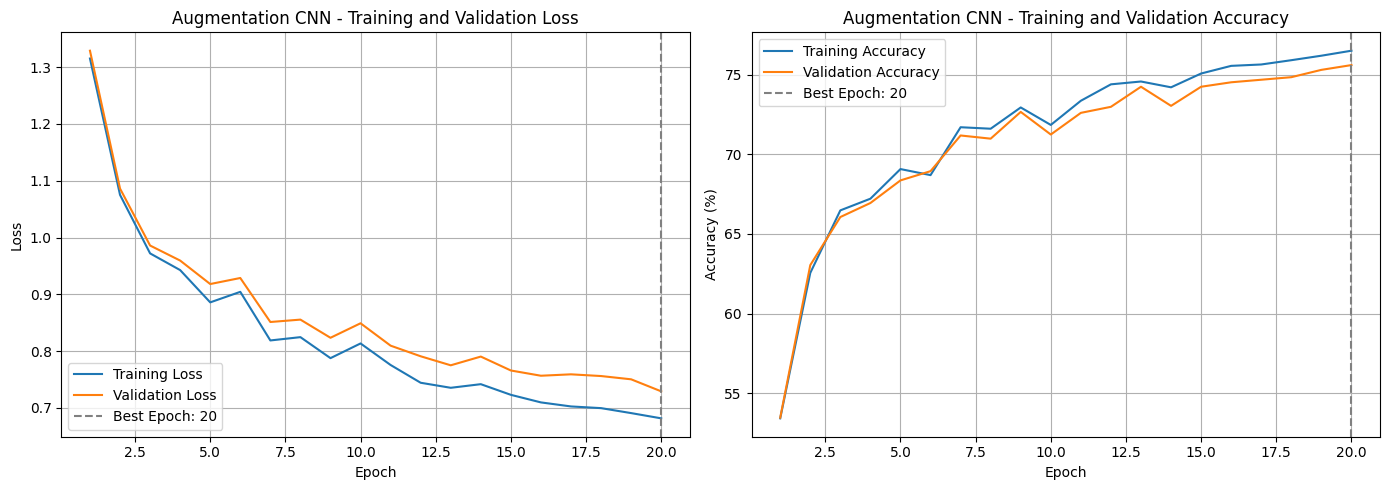

In [19]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(epochs_range, augmentation_history["train_loss"], label="Training Loss")
axes[0].plot(epochs_range, augmentation_history["validation_loss"], label="Validation Loss")
axes[0].axvline(augmentation_best_epoch, linestyle="--", color="grey",
                label=f"Best Epoch: {augmentation_best_epoch}")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Augmentation CNN - Training and Validation Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_range, augmentation_history["train_accuracy"], label="Training Accuracy")
axes[1].plot(epochs_range, augmentation_history["validation_accuracy"], label="Validation Accuracy")
axes[1].axvline(augmentation_best_epoch, linestyle="--", color="grey",
                label=f"Best Epoch: {augmentation_best_epoch}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Augmentation CNN - Training and Validation Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("augmentation_loss_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

# Data Augmentation Experiment Results

The model was trained for 20 epochs and the checkpoint with the highest validation accuracy was selected. Training accuracy and loss are measured on the non-augmented training images.

In [20]:
print("DATA AUGMENTATION EXPERIMENT SUMMARY")
print("-" * 40)

print(f"Best epoch: {augmentation_best_epoch}")
print(f"Training accuracy: {aug_train_accuracy:.2f}%")
print(f"Validation accuracy: {aug_val_accuracy:.2f}%")
print(f"Test accuracy: {aug_test_accuracy:.2f}%")

print(f"Training loss: {aug_train_loss:.4f}")
print(f"Validation loss: {aug_val_loss:.4f}")
print(f"Test loss: {aug_test_loss:.4f}")

print(f"Accuracy gap (train - validation): {aug_accuracy_gap:.2f} percentage points")
print(f"Accuracy gap (train - test): {aug_train_accuracy - aug_test_accuracy:.2f} percentage points")
print(f"Trainable parameters: {augmentation_parameters}")
print(f"Training time: {augmentation_training_time:.2f} seconds")

DATA AUGMENTATION EXPERIMENT SUMMARY
----------------------------------------
Best epoch: 20
Training accuracy: 76.50%
Validation accuracy: 75.60%
Test accuracy: 74.68%
Training loss: 0.6818
Validation loss: 0.7293
Test loss: 0.7414
Accuracy gap (train - validation): 0.90 percentage points
Accuracy gap (train - test): 1.82 percentage points
Trainable parameters: 60362
Training time: 578.26 seconds


# Baseline vs Augmentation Comparison

The augmentation result is compared with the unchanged baseline. The dropout row is included for reference only; each technique was trained and evaluated independently against the same baseline.

The baseline and dropout values below are the recorded results from Exercise 2 and the dropout run above, so this comparison can be reproduced without retraining those models. The **train–test gap** (training accuracy − test accuracy, in percentage points) is the generalisation measure used for Exercise 3.

In [21]:
# Recorded values
recorded_dropout_results = {
    "Experiment": "Dropout (p=0.3)",
    "Best Epoch": 19,
    "Train Accuracy (%)": 85.58,
    "Validation Accuracy (%)": 75.08,
    "Test Accuracy (%)": 74.68,
    "Train Loss": 0.4343,
    "Validation Loss": 0.7602,
    "Test Loss": 0.7663,
    "Parameters": 60362,
}

comparison_rows = []
for change, result in [
    ("None", baseline_results),
    ("Dropout only", recorded_dropout_results),
    ("Training transforms only", augmentation_results),
]:
    comparison_rows.append({
        "Condition": result["Experiment"],
        "Change from baseline": change,
        "Best Epoch": result["Best Epoch"],
        "Train Accuracy (%)": round(result["Train Accuracy (%)"], 2),
        "Validation Accuracy (%)": round(result["Validation Accuracy (%)"], 2),
        "Test Accuracy (%)": round(result["Test Accuracy (%)"], 2),
        "Train-Test Gap (pp)": round(result["Train Accuracy (%)"] - result["Test Accuracy (%)"], 2),
        "Train-Validation Gap (pp)": round(result["Train Accuracy (%)"] - result["Validation Accuracy (%)"], 2),
        "Test Loss": round(result["Test Loss"], 4),
        "Parameters": result["Parameters"],
    })

exercise3_comparison_df = pd.DataFrame(comparison_rows)
display(exercise3_comparison_df)
exercise3_comparison_df.to_csv("exercise3_results.csv", index=False)
print("Saved exercise3_results.csv")

,Condition,Change from baseline,Best Epoch,Train Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Train-Test Gap (pp),Train-Validation Gap (pp),Test Loss,Parameters
0,Baseline CNN,None,14,84.75,71.82,70.72,14.03,12.93,0.9504,60362
1,Dropout (p=0.3),Dropout only,19,85.58,75.08,74.68,10.90,10.50,0.7663,60362
2,Data Augmentation (crop + flip),Training transforms only,20,76.50,75.60,74.68,1.82,0.90,0.7414,60362


Saved exercise3_results.csv


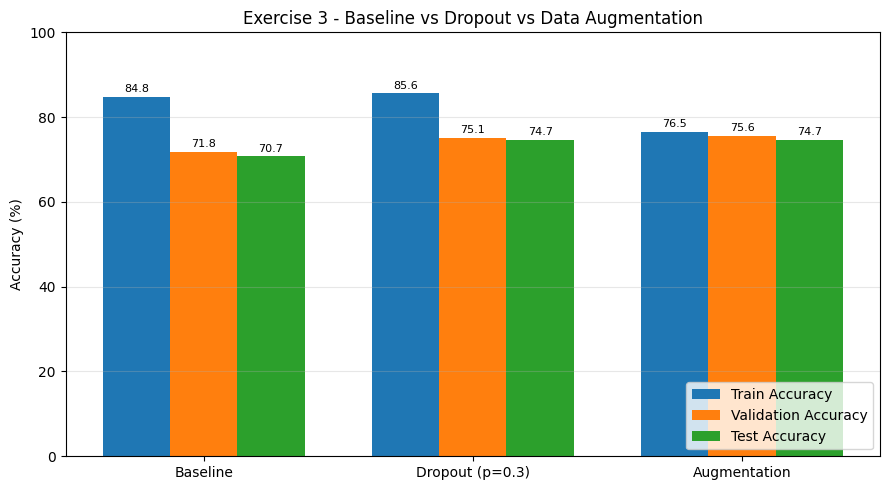

In [22]:
labels = ["Baseline", "Dropout (p=0.3)", "Augmentation"]
metrics = ["Train Accuracy (%)", "Validation Accuracy (%)", "Test Accuracy (%)"]
x = np.arange(len(labels))
bar_width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
for i, metric in enumerate(metrics):
    values = exercise3_comparison_df[metric].values
    bars = ax.bar(x + (i - 1) * bar_width, values, bar_width, label=metric.replace(" (%)", ""))
    ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Exercise 3 - Baseline vs Dropout vs Data Augmentation")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("exercise3_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
base = exercise3_comparison_df.iloc[0]
aug  = exercise3_comparison_df.iloc[2]

print("AUGMENTATION vs BASELINE (augmentation minus baseline)")
print("-" * 55)
print(f"Training accuracy change:   {aug['Train Accuracy (%)'] - base['Train Accuracy (%)']:+.2f} pp")
print(f"Validation accuracy change: {aug['Validation Accuracy (%)'] - base['Validation Accuracy (%)']:+.2f} pp")
print(f"Test accuracy change:       {aug['Test Accuracy (%)'] - base['Test Accuracy (%)']:+.2f} pp")
print(f"Train-test gap:             {base['Train-Test Gap (pp)']:.2f} pp -> {aug['Train-Test Gap (pp)']:.2f} pp")
print(f"Test loss:                  {base['Test Loss']:.4f} -> {aug['Test Loss']:.4f}")

AUGMENTATION vs BASELINE (augmentation minus baseline)
-------------------------------------------------------
Training accuracy change:   -8.25 pp
Validation accuracy change: +3.78 pp
Test accuracy change:       +3.96 pp
Train-test gap:             14.03 pp -> 1.82 pp
Test loss:                  0.9504 -> 0.7414


**Discussion of data augmentation**

Data augmentation does not change the model: the parameter count stays at 60,362. Instead, it changes what the model sees during training. Because every epoch shows a slightly different shifted or mirrored version of each image, the network cannot simply memorise the exact pixels of the 45,000 training images and has to learn features that still work when the object moves or is flipped. This makes the training task harder, so training accuracy is expected to rise more slowly, while the features learned should transfer better to unseen validation and test images.

The measured changes in training accuracy, test accuracy and the train–test gap are shown in the comparison above. These conclusions come from a single run with seed 42, so small differences should be interpreted with caution.